<a name = "inicio"></a>

***

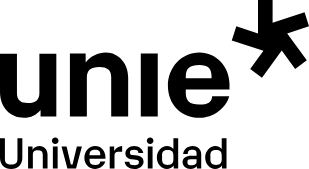

***

**Laboratorio realizado en equipo.**

***

# Instrucciones de la prueba

Este documento corresponde al **Laboratorio 3.1** que tenéis que realizar en equipo abarcando los conceptos vistos en el **Notebook 3.1**. Un alumno en representación del grupo deberá de entregar este mismo notebook con las respuestas a través de la plataforma **Blackboard** llamando al archivo **Lab3.1_No.Grupo**. El profesor publicará la resolución de todos los ejercicios con posterioridad. ¡Mucha suerte y ánimo a tod@s!

**<mark>Nota.-**<mark><div style="background-color:#F7DC6F"><b> Tened en cuenta que deberéis de aportar respuestas detalladas y bien justificadas. No es admisible adjuntar únicamente el código sin comentar. Hay que incluir paso a paso lo que estáis haciendo en las propias celdas del código. Además, deberéis de razonar, argumentar e INTERPRETAR los resultados obtenidos con vuestras propias palabras según el contexto de cada ejercicio utilizando para ello celdas tipo Markdown. </b></div>

***

### Ejercicio 1

Considerar la información de la base de datos `airquality` de la librería $\tt datasets$, que consiste en $154$ medidas (de $6$ variables) de calidad del aire en Nueva York en los últimos tiempos. La variable dependiente `Ozone` que es la concentración media de ozono en la atmósfera (en ppb, partes por billón) se quiere explicar a partir de la variable independiente `Temp` que nos indica la temperatura máxima diaria (en grados Fahrenheit). Realizar los siguientes apartados:

1. Exploración inicial de la base de datos
2. Análisis de la existencia de relación lineal entre las variables
3. Estimación de un modelo de regresión lineal simple entre las variables
4. Interpretación de las salidas de estimación de un modelo de regresión lineal simple

<div style="background-color:#F7DC6F"><b>Resolución Ejercicio 01</b></div>

<div style="background-color:#5DADE2"><b>Apartado 1</b></div>

In [1]:
# Cargar la librería datasets
if(!require(datasets)){install.packages("datasets")}
library(datasets)

# Resumen estadístico de las variables
summary(airquality)

# Dimensiones de la base de datos
dim(airquality)

# Estructura de la base de datos
str(airquality)

# Primeros 6 registros de la base de datos
head(airquality)

# Valores perdidos por variable
colSums(is.na(airquality))

     Ozone           Solar.R           Wind             Temp      
 Min.   :  1.00   Min.   :  7.0   Min.   : 1.700   Min.   :56.00  
 1st Qu.: 18.00   1st Qu.:115.8   1st Qu.: 7.400   1st Qu.:72.00  
 Median : 31.50   Median :205.0   Median : 9.700   Median :79.00  
 Mean   : 42.13   Mean   :185.9   Mean   : 9.958   Mean   :77.88  
 3rd Qu.: 63.25   3rd Qu.:258.8   3rd Qu.:11.500   3rd Qu.:85.00  
 Max.   :168.00   Max.   :334.0   Max.   :20.700   Max.   :97.00  
 NA's   :37       NA's   :7                                       
     Month            Day      
 Min.   :5.000   Min.   : 1.0  
 1st Qu.:6.000   1st Qu.: 8.0  
 Median :7.000   Median :16.0  
 Mean   :6.993   Mean   :15.8  
 3rd Qu.:8.000   3rd Qu.:23.0  
 Max.   :9.000   Max.   :31.0  
                               

[1] 153   6

'data.frame':	153 obs. of  6 variables:
 $ Ozone  : int  41 36 12 18 NA 28 23 19 8 NA ...
 $ Solar.R: int  190 118 149 313 NA NA 299 99 19 194 ...
 $ Wind   : num  7.4 8 12.6 11.5 14.3 14.9 8.6 13.8 20.1 8.6 ...
 $ Temp   : int  67 72 74 62 56 66 65 59 61 69 ...
 $ Month  : int  5 5 5 5 5 5 5 5 5 5 ...
 $ Day    : int  1 2 3 4 5 6 7 8 9 10 ...


,Ozone,Solar.R,Wind,Temp,Month,Day
,<int>,<int>,<dbl>,<int>,<int>,<int>
1,41,190,7.4,67,5,1
2,36,118,8.0,72,5,2
3,12,149,12.6,74,5,3
4,18,313,11.5,62,5,4
5,NA,NA,14.3,56,5,5
6,28,NA,14.9,66,5,6


Ozone Solar.R    Wind    Temp   Month     Day 
     37       7       0       0       0       0

<div style="background-color:#5DADE2"><b>Apartado 2</b></div>

[1] 0.6983603

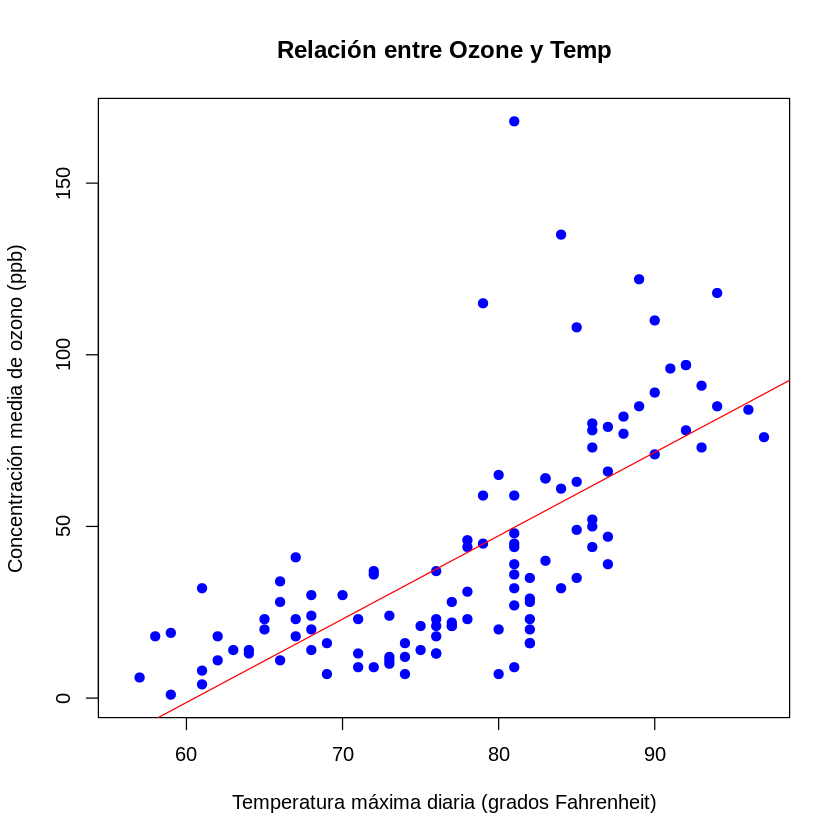

In [2]:
# Gráfico de dispersión de Ozone vs Temp
plot(airquality$Temp, airquality$Ozone,
     main = "Relación entre Ozone y Temp",
     xlab = "Temperatura máxima diaria (grados Fahrenheit)",
     ylab = "Concentración media de ozono (ppb)",
     col = "blue", pch = 19)

# Calcular la correlación lineal entre Ozone y Temp (excluyendo valores perdidos)
cor_ozone_temp <- cor(airquality$Ozone, airquality$Temp, use = "complete.obs")
cor_ozone_temp

# Añadir la línea de regresión al gráfico
abline(lm(Ozone ~ Temp, data = airquality), col = "red")


## Interpretación de la correlación:
Si cor_ozone_temp es cercano a 1, indica una correlación positiva fuerte
Si cor_ozone_temp es cercano a -1, indica una correlación negativa fuerte
Si cor_ozone_temp es cercano a 0, indica una correlación débil o inexistente
El gráfico de dispersión nos ayuda a visualizar la relación entre las variables.

<div style="background-color:#5DADE2"><b>Apartado 3</b></div>

In [3]:
# Estimación del modelo de regresión lineal simple
modelo <- lm(Ozone ~ Temp, data = airquality)

# Resumen del modelo
summary(modelo)
# <div style="background-color:#5DADE2"><b>Apartado 4</b></div>


Call:
lm(formula = Ozone ~ Temp, data = airquality)

Residuals:
    Min      1Q  Median      3Q     Max 
-40.729 -17.409  -0.587  11.306 118.271 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -146.9955    18.2872  -8.038 9.37e-13 ***
Temp           2.4287     0.2331  10.418  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 23.71 on 114 degrees of freedom
  (37 observations deleted due to missingness)
Multiple R-squared:  0.4877,	Adjusted R-squared:  0.4832 
F-statistic: 108.5 on 1 and 114 DF,  p-value: < 2.2e-16


## Interpretación de las salidas del modelo:
Coeficientes: Intercept y pendiente de la recta de regresión
R-cuadrado: Proporción de variabilidad en Ozone explicada por Temp
p-valor: Significancia estadística de la relación entre las variables
Otros estadísticos: Error estándar de los residuos, etc.

## Ejemplo de interpretación de los coeficientes:
El coeficiente de Temp indica el cambio promedio en la concentración de ozono por cada grado Fahrenheit adicional de temperatura máxima diaria.
El coeficiente de intersección representa el valor predicho de Ozone cuando Temp = 0.

<div style="background-color:#5DADE2"><b>Apartado 4</b></div>

In [5]:
# Cargar la librería datasets
if(!require(datasets)){install.packages("datasets")}
# Load the datasets library
library(datasets) # This line is added to load the library

# Exploración inicial de la base de datos airquality
# Resumen estadístico de las variables
summary(airquality)

# Dimensiones de la base de datos
dim(airquality)

# Estructura de la base de datos
str(airquality)

# Primeros 6 registros de la base de datos
head(airquality)

# Valores perdidos por variable
colSums(is.na(airquality))

     Ozone           Solar.R           Wind             Temp      
 Min.   :  1.00   Min.   :  7.0   Min.   : 1.700   Min.   :56.00  
 1st Qu.: 18.00   1st Qu.:115.8   1st Qu.: 7.400   1st Qu.:72.00  
 Median : 31.50   Median :205.0   Median : 9.700   Median :79.00  
 Mean   : 42.13   Mean   :185.9   Mean   : 9.958   Mean   :77.88  
 3rd Qu.: 63.25   3rd Qu.:258.8   3rd Qu.:11.500   3rd Qu.:85.00  
 Max.   :168.00   Max.   :334.0   Max.   :20.700   Max.   :97.00  
 NA's   :37       NA's   :7                                       
     Month            Day      
 Min.   :5.000   Min.   : 1.0  
 1st Qu.:6.000   1st Qu.: 8.0  
 Median :7.000   Median :16.0  
 Mean   :6.993   Mean   :15.8  
 3rd Qu.:8.000   3rd Qu.:23.0  
 Max.   :9.000   Max.   :31.0  
                               

[1] 153   6

'data.frame':	153 obs. of  6 variables:
 $ Ozone  : int  41 36 12 18 NA 28 23 19 8 NA ...
 $ Solar.R: int  190 118 149 313 NA NA 299 99 19 194 ...
 $ Wind   : num  7.4 8 12.6 11.5 14.3 14.9 8.6 13.8 20.1 8.6 ...
 $ Temp   : int  67 72 74 62 56 66 65 59 61 69 ...
 $ Month  : int  5 5 5 5 5 5 5 5 5 5 ...
 $ Day    : int  1 2 3 4 5 6 7 8 9 10 ...


,Ozone,Solar.R,Wind,Temp,Month,Day
,<int>,<int>,<dbl>,<int>,<int>,<int>
1,41,190,7.4,67,5,1
2,36,118,8.0,72,5,2
3,12,149,12.6,74,5,3
4,18,313,11.5,62,5,4
5,NA,NA,14.3,56,5,5
6,28,NA,14.9,66,5,6


Ozone Solar.R    Wind    Temp   Month     Day 
     37       7       0       0       0       0

### Ejercicio 2

El dataframe `Boston` de la librería $\tt MASS$ contiene información de propiedades inmobiliarias de la ciudad de Boston. Cada propiedad está caracterizada por $13$ variables que indican las características de la misma, así como por la variable `medv` que representa una estimación del valor de la propiedad en miles de dólares. Considerando la variable dependiente `medv` en función de la variable independiente `crim` que representa la tasa de crimen per capita de los distritos a los que pertenece cada una de las viviendas realizar los siguientes apartados:

1. Exploración inicial de la base de datos
2. Análisis de la existencia de relación lineal entre las variables
3. Estimación de un modelo de regresión lineal simple entre las variables
4. Interpretación de las salidas de estimación de un modelo de regresión lineal simple

<div style="background-color:#F7DC6F"><b>Resolución Ejercicio 02</b></div>

<div style="background-color:#5DADE2"><b>Apartado 1</b></div>

<div style="background-color:#5DADE2"><b>Apartado 2</b></div>

<div style="background-color:#5DADE2"><b>Apartado 3</b></div>

<div style="background-color:#5DADE2"><b>Apartado 4</b></div>

### Ejercicio 3

Utilizando el dataset `airquality` encontrar el mejor modelo de regresión lineal simple de la variable dependiente `Ozone` en función de las siguientes variables (considerar una a una): `Temp` que nos indica la temperatura máxima diaria (en grados Fahrenheit), `Solar.R` que mide la radiación solar (en Ly, Langleys) y la variable `Wind` que recoge la información sobre la velocidad media del viento (en mph, millas por hora). Comparar sus métricas y realizar la diagnosis del modelo de regresión lineal elegido. Es decir, tenéis que hacer los pasos incluidos en el apartado no. $5$ del Notebook teórico:

1. Criterios de selección del modelo en base al ajuste de los datos
2. Modificaciones del modelo de regresión lineal simple seleccionado
3. Requisitos y validación del mejor modelo seleccionado en base al ajuste de los datos

<div style="background-color:#F7DC6F"><b>Resolución Ejercicio 03</b></div>

<div style="background-color:#5DADE2"><b>Apartado 1</b></div>


Call:
lm(formula = Ozone ~ Temp, data = airquality_clean)

Residuals:
    Min      1Q  Median      3Q     Max 
-40.922 -17.459  -0.874  10.444 118.078 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -147.6461    18.7553  -7.872 2.76e-12 ***
Temp           2.4391     0.2393  10.192  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 23.92 on 109 degrees of freedom
Multiple R-squared:  0.488,	Adjusted R-squared:  0.4833 
F-statistic: 103.9 on 1 and 109 DF,  p-value: < 2.2e-16



Call:
lm(formula = Ozone ~ Solar.R, data = airquality_clean)

Residuals:
    Min      1Q  Median      3Q     Max 
-48.292 -21.361  -8.864  16.373 119.136 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 18.59873    6.74790   2.756 0.006856 ** 
Solar.R      0.12717    0.03278   3.880 0.000179 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 31.33 on 109 degrees of freedom
Multiple R-squared:  0.1213,	Adjusted R-squared:  0.1133 
F-statistic: 15.05 on 1 and 109 DF,  p-value: 0.0001793



Call:
lm(formula = Ozone ~ Wind, data = airquality_clean)

Residuals:
    Min      1Q  Median      3Q     Max 
-43.513 -18.597  -5.035  15.814  88.437 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  99.0413     7.4724   13.25  < 2e-16 ***
Wind         -5.7288     0.7082   -8.09 9.09e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 26.42 on 109 degrees of freedom
Multiple R-squared:  0.3752,	Adjusted R-squared:  0.3694 
F-statistic: 65.44 on 1 and 109 DF,  p-value: 9.089e-13


R-squared para Temp: 0.4879601 
R-squared para Solar.R: 0.1213419 
R-squared para Wind: 0.3751521 


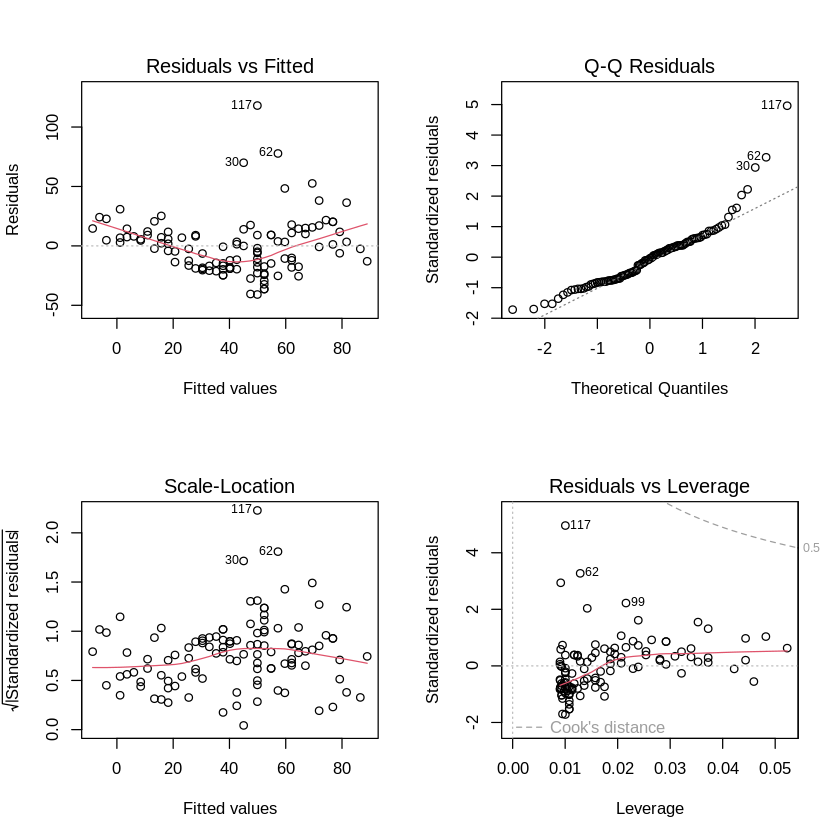

In [13]:
# Cargar librerías necesarias
library(datasets)
library(ggplot2)

# Eliminar filas con valores NA en las variables de interés
airquality_clean <- na.omit(airquality)

# Crear modelos de regresión
model_temp <- lm(Ozone ~ Temp, data = airquality_clean)
model_solar <- lm(Ozone ~ Solar.R, data = airquality_clean)
model_wind <- lm(Ozone ~ Wind, data = airquality_clean)

# Resumen de los modelos
summary(model_temp)
summary(model_solar)
summary(model_wind)

# Comparar R-squared
r_squared_temp <- summary(model_temp)$r.squared
r_squared_solar <- summary(model_solar)$r.squared
r_squared_wind <- summary(model_wind)$r.squared

# Imprimir R-squared de cada modelo
cat("R-squared para Temp:", r_squared_temp, "\n")
cat("R-squared para Solar.R:", r_squared_solar, "\n")
cat("R-squared para Wind:", r_squared_wind, "\n")

# Seleccionar el mejor modelo basado en R-squared
best_model <- model_temp
if (r_squared_solar > r_squared_temp && r_squared_solar > r_squared_wind) {
  best_model <- model_solar
} else if (r_squared_wind > r_squared_temp && r_squared_wind > r_squared_solar) {
  best_model <- model_wind
}

# Diagnóstico del mejor modelo
par(mfrow = c(2, 2))  # Configurar una cuadrícula de 2x2 para gráficos
plot(best_model)


<div style="background-color:#5DADE2"><b>Apartado 2</b></div>

Basándonos en los gráficos de diagnóstico del Apartado 1,
Podemos identificar posibles problemas y aplicar transformaciones
o modificaciones al modelo para mejorarlo.

Ejemplo: Si el gráfico de residuos vs. ajustados muestra una
heterocedasticidad (variabilidad no constante de los residuos),
podemos transformar la variable respuesta (Ozone) o la variable predictora (la elegida en el apartado anterior)

In [11]:


# Ejemplo de transformación logarítmica de Ozone:
model_transformed <- lm(log(Ozone) ~ Temp, data = airquality_clean)
summary(model_transformed)




Call:
lm(formula = log(Ozone) ~ Temp, data = airquality_clean)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.14417 -0.32555  0.02066  0.34234  1.49100 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.848518   0.455080  -4.062  9.2e-05 ***
Temp         0.067673   0.005807  11.654  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.5804 on 109 degrees of freedom
Multiple R-squared:  0.5548,	Adjusted R-squared:  0.5507 
F-statistic: 135.8 on 1 and 109 DF,  p-value: < 2.2e-16


Comparar los modelos original y transformado
Analizar los gráficos de diagnóstico del nuevo modelo

Otro ejemplo: Si se detecta una no linealidad,
se podría incluir un término cuadrático en el modelo
model_quadratic <- lm(Ozone ~ Temp + I(Temp^2), data = airquality_clean)

Comparar el R-cuadrado ajustado, el AIC y el BIC de ambos modelos para determinar cuál es el mejor.

Selecciona el modelo que mejor se ajuste a los datos según los criterios mencionados anteriormente.

<div style="background-color:#5DADE2"><b>Apartado 3</b></div>

In [12]:
# Ejemplo de comprobación de normalidad
shapiro.test(residuals(best_model)) # o residuals(model_transformed) según el modelo elegido


	Shapiro-Wilk normality test

data:  residuals(best_model)
W = 0.88983, p-value = 1.522e-07


Una vez que hemos realizado las modificaciones necesarias en el apartado anterior,
debemos validar el modelo final para asegurarnos de que cumple con los requisitos
de un buen modelo de regresión lineal.
1. Linealidad: Los gráficos de diagnóstico deben mostrar una relación lineal entre
los valores ajustados y los residuos.

2. Independencia: Los residuos deben ser independientes entre sí. Se puede comprobar
con el gráfico de residuos vs. orden de observación.

3. Homocedasticidad: La varianza de los residuos debe ser constante a lo largo de los
valores ajustados. Se puede comprobar con el gráfico de escala-ubicación.

4. Normalidad: Los residuos deben seguir una distribución normal. Se puede comprobar
con el gráfico Q-Q y con pruebas de normalidad como el test de Shapiro-Wilk.

5. Ausencia de valores atípicos influyentes: Se debe comprobar si hay observaciones
atípicas que influyen significativamente en los coeficientes de regresión.

Para validar el mejor modelo, repetiremos el análisis de diagnóstico del apartado 1
con el modelo final.

Interpretación del resultado del test de Shapiro-Wilk:
Si el p-valor es mayor que un nivel de significancia predefinido (por ejemplo, 0.05),
no rechazamos la hipótesis nula de que los residuos siguen una distribución normal.

Si alguna de las suposiciones no se cumple, se podría explorar otras transformaciones
de las variables o considerar modelos de regresión alternativos.

### Ejercicio 4

Utilizando el dataset `Boston` encontrar el mejor modelo de regresión lineal simple de la variable `medv` en función del resto de variables excepto `chas` y `rad` (considerar una a una). Comparar sus métricas y realizar la diagnosis del modelo de regresión lineal elegido. Es decir, tenéis que hacer los pasos incluidos en el apartado no. $5$ del Notebook teórico:

1. Criterios de selección del modelo en base al ajuste de los datos
2. Modificaciones del modelo de regresión lineal simple seleccionado
3. Requisitos y validación del mejor modelo seleccionado en base al ajuste de los datos

<div style="background-color:#F7DC6F"><b>Resolución Ejercicio 04</b></div>

<div style="background-color:#5DADE2"><b>Apartado 1</b></div>

<div style="background-color:#5DADE2"><b>Apartado 2</b></div>

<div style="background-color:#5DADE2"><b>Apartado 3</b></div>

<div style = "float:right"><a style="text-decoration:none" href = "#inicio">Inicio</a></div>